In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import matplotlib.pyplot as plt
import numpy as np
import random
import time
from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


# Homework 8: Mini Diffusion Model

## DDPM and DDIM on MNIST

This notebook implements a simplified diffusion model using the MNIST dataset. The project includes forward diffusion, training a timestep conditioned CNN to predict noise, DDPM reverse sampling, and DDIM sampling with reduced numbers of sampling steps.

### Configuration

* Diffusion steps: T = 100
* Beta schedule: linear from 0.0001 to 0.02
* Batch size: 128
* Training epochs: 50
* Dataset: MNIST

In [3]:
IMAGE_SIZE = 28
BATCH_SIZE = 128
NUM_WORKERS = 2

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Number of training images:", len(train_dataset))
print("Number of batches:", len(train_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:", images.min().item(), "to", images.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 469kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.12MB/s]

Number of training images: 60000
Number of batches: 469


Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Pixel value range: -1.0 to 1.0


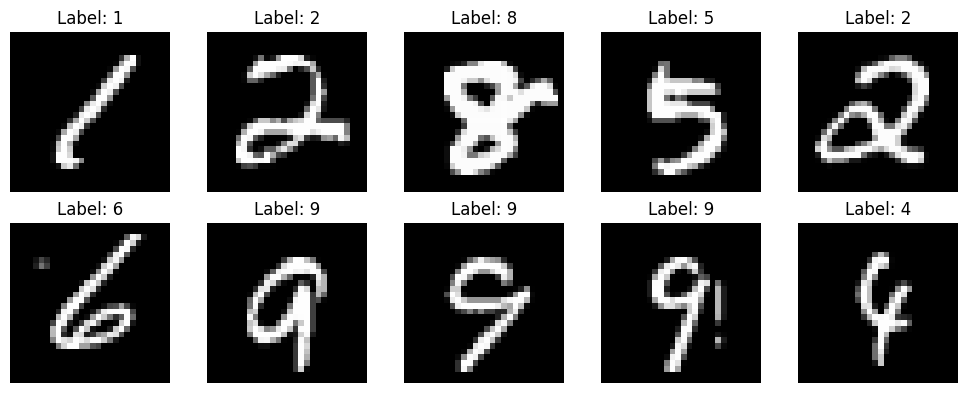

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().cpu()
    image = (image + 1) / 2

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Part A: Forward Diffusion

The forward diffusion process gradually adds Gaussian noise to a clean image. A linear noise schedule is used with 100 diffusion steps, starting from beta = 0.0001 and ending at beta = 0.02.

In [5]:
T = 100

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(beta_start, beta_end, T, device=device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

print("Number of diffusion steps:", T)
print("Beta shape:", betas.shape)
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())
print("First alpha_bar:", alpha_bars[0].item())
print("Last alpha_bar:", alpha_bars[-1].item())

Number of diffusion steps: 100
Beta shape: torch.Size([100])
First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164
First alpha_bar: 0.9998999834060669
Last alpha_bar: 0.36356320977211


In [6]:
def forward_diffusion(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )

    return xt, noise

In [7]:
test_images = images[:8].to(device)

test_t = torch.full(
    (test_images.size(0),),
    49,
    device=device,
    dtype=torch.long
)

noisy_images, sampled_noise = forward_diffusion(
    test_images,
    test_t
)

print("Original shape:", test_images.shape)
print("Noisy image shape:", noisy_images.shape)
print("Noise shape:", sampled_noise.shape)

print(
    "Contains NaN:",
    torch.isnan(noisy_images).any().item()
)

Original shape: torch.Size([8, 1, 28, 28])
Noisy image shape: torch.Size([8, 1, 28, 28])
Noise shape: torch.Size([8, 1, 28, 28])
Contains NaN: False


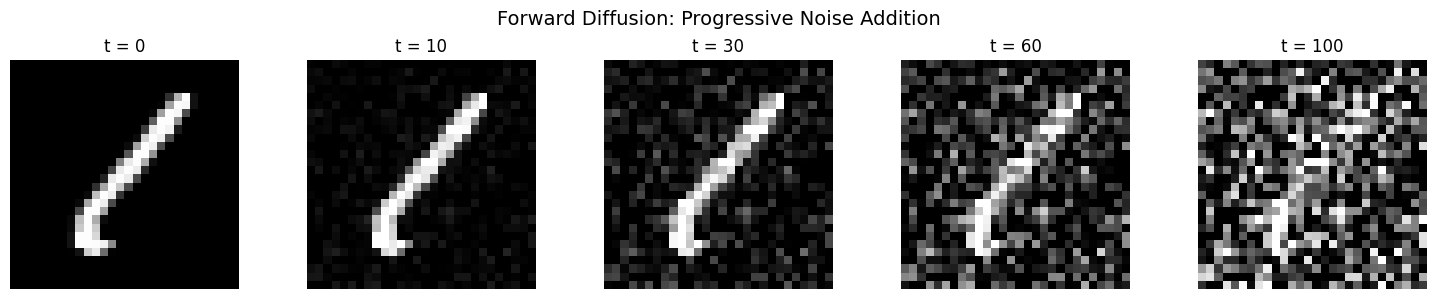

In [8]:
x0 = images[0:1].to(device)

display_steps = [0, 10, 30, 60, 100]

fixed_noise = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(display_steps), figsize=(15, 3))

for ax, step in zip(axes, display_steps):

    if step == 0:
        xt = x0
    else:
        t_index = step - 1

        t = torch.tensor(
            [t_index],
            device=device,
            dtype=torch.long
        )

        xt, _ = forward_diffusion(
            x0,
            t,
            noise=fixed_noise
        )

    image_to_show = xt.squeeze().detach().cpu()
    image_to_show = (image_to_show + 1) / 2

    ax.imshow(
        image_to_show,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"t = {step}")
    ax.axis("off")

plt.suptitle(
    "Forward Diffusion: Progressive Noise Addition",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Forward Diffusion Observation

The visualization shows the gradual corruption of an MNIST image as the diffusion timestep increases. At early timesteps, the digit remains clearly recognizable because only a small amount of Gaussian noise has been added. As the timestep increases, the cumulative noise becomes stronger and the original image structure becomes progressively less visible. By the final timestep, noise dominates much of the image, demonstrating the forward diffusion process that the model will later learn to reverse.

## Part B: Mini DDPM Noise Prediction Network

The reverse diffusion model is trained to predict the Gaussian noise added to an MNIST image at a randomly selected diffusion timestep. The CNN is conditioned on the timestep so that it can learn how the amount of noise changes throughout the diffusion process.

In [9]:
class NoisePredictor(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()

        self.time_dim = time_dim

        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.ReLU(),
            nn.Linear(time_dim, time_dim),
            nn.ReLU()
        )

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(32, 1, kernel_size=3, padding=1)

        self.time_to_channels = nn.Linear(time_dim, 64)

    def forward(self, x, t):
        t = t.float().unsqueeze(1) / T

        time_embedding = self.time_mlp(t)
        time_embedding = self.time_to_channels(time_embedding)
        time_embedding = time_embedding[:, :, None, None]

        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        x = x + time_embedding

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.conv5(x)

        return x


model = NoisePredictor().to(device)

print(model)

num_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {num_parameters:,}")

NoisePredictor(
  (time_mlp): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_to_channels): Linear(in_features=64, out_features=64, bias=True)
)

Trainable parameters: 82,945


In [10]:
test_x = images[:8].to(device)

test_t = torch.randint(
    0,
    T,
    (test_x.size(0),),
    device=device
)

with torch.no_grad():
    test_output = model(test_x, test_t)

print("Input shape:", test_x.shape)
print("Timestep shape:", test_t.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == test_x.shape

print("Shape check passed.")

Input shape: torch.Size([8, 1, 28, 28])
Timestep shape: torch.Size([8])
Output shape: torch.Size([8, 1, 28, 28])
Shape check passed.


In [11]:
criterion = nn.MSELoss()

sample_images = images[:8].to(device)

sample_t = torch.randint(
    0,
    T,
    (sample_images.size(0),),
    device=device,
    dtype=torch.long
)

noisy_sample, true_noise = forward_diffusion(
    sample_images,
    sample_t
)

predicted_noise = model(
    noisy_sample,
    sample_t
)

test_loss = criterion(
    predicted_noise,
    true_noise
)

print("Clean images:", sample_images.shape)
print("Noisy images:", noisy_sample.shape)
print("True noise:", true_noise.shape)
print("Predicted noise:", predicted_noise.shape)
print("Initial MSE loss:", test_loss.item())

assert torch.isfinite(test_loss)

print("Loss check passed.")

Clean images: torch.Size([8, 1, 28, 28])
Noisy images: torch.Size([8, 1, 28, 28])
True noise: torch.Size([8, 1, 28, 28])
Predicted noise: torch.Size([8, 1, 28, 28])
Initial MSE loss: 1.0126333236694336
Loss check passed.


### Training Configuration

The noise prediction network is trained by sampling a random diffusion timestep for each image, adding Gaussian noise using the forward diffusion process, and minimizing the mean squared error between the true noise and the predicted noise.

In [12]:
LEARNING_RATE = 1e-3
NUM_EPOCHS = 50

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.MSELoss()

training_losses = []
epoch_times = []

print("Training configuration")
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss: MSE")
print("Device:", device)

Training configuration
Epochs: 50
Batch size: 128
Learning rate: 0.001
Optimizer: Adam
Loss: MSE
Device: cuda


In [13]:
training_start_time = time.time()

for epoch in range(NUM_EPOCHS):
    model.train()

    epoch_start_time = time.time()
    running_loss = 0.0

    for batch_images, _ in train_loader:
        batch_images = batch_images.to(device)

        batch_size = batch_images.size(0)

        t = torch.randint(
            0,
            T,
            (batch_size,),
            device=device,
            dtype=torch.long
        )

        noisy_images, true_noise = forward_diffusion(
            batch_images,
            t
        )

        predicted_noise = model(
            noisy_images,
            t
        )

        loss = criterion(
            predicted_noise,
            true_noise
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    epoch_time = time.time() - epoch_start_time

    training_losses.append(average_loss)
    epoch_times.append(epoch_time)

    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
        f"Loss: {average_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

total_training_time = time.time() - training_start_time

print()
print("Training complete")
print(f"Initial epoch loss: {training_losses[0]:.6f}")
print(f"Final epoch loss: {training_losses[-1]:.6f}")
print(f"Best epoch loss: {min(training_losses):.6f}")
print(f"Total training time: {total_training_time:.2f}s")

Epoch 01/50 | Loss: 0.156066 | Time: 13.10s
Epoch 02/50 | Loss: 0.087733 | Time: 12.56s
Epoch 03/50 | Loss: 0.080872 | Time: 13.01s
Epoch 04/50 | Loss: 0.076872 | Time: 12.72s
Epoch 05/50 | Loss: 0.076468 | Time: 12.56s
Epoch 06/50 | Loss: 0.073553 | Time: 12.62s
Epoch 07/50 | Loss: 0.073220 | Time: 12.75s
Epoch 08/50 | Loss: 0.071201 | Time: 12.63s
Epoch 09/50 | Loss: 0.070399 | Time: 12.88s
Epoch 10/50 | Loss: 0.070624 | Time: 12.63s
Epoch 11/50 | Loss: 0.069324 | Time: 12.99s
Epoch 12/50 | Loss: 0.069390 | Time: 12.66s
Epoch 13/50 | Loss: 0.068681 | Time: 12.70s
Epoch 14/50 | Loss: 0.068103 | Time: 12.69s
Epoch 15/50 | Loss: 0.068243 | Time: 12.52s
Epoch 16/50 | Loss: 0.067014 | Time: 12.65s
Epoch 17/50 | Loss: 0.066881 | Time: 12.77s
Epoch 18/50 | Loss: 0.066586 | Time: 12.69s
Epoch 19/50 | Loss: 0.066701 | Time: 12.40s
Epoch 20/50 | Loss: 0.066353 | Time: 12.42s
Epoch 21/50 | Loss: 0.065744 | Time: 12.75s
Epoch 22/50 | Loss: 0.065597 | Time: 12.60s
Epoch 23/50 | Loss: 0.066028 | T

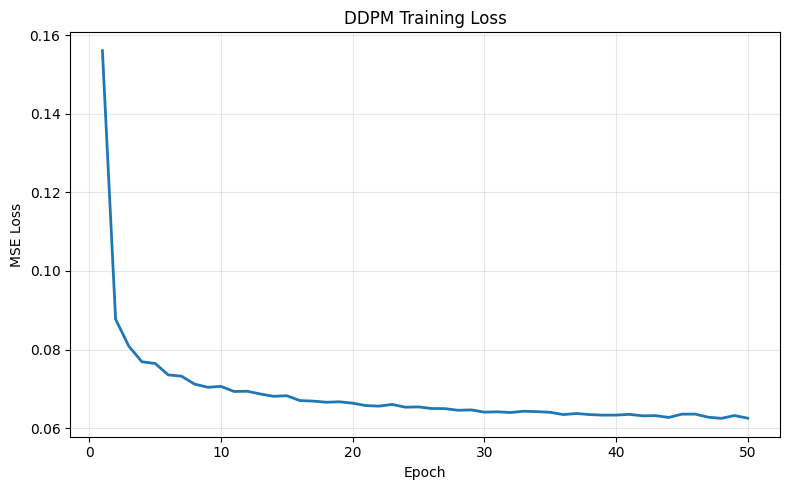

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    training_losses,
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
best_epoch = int(np.argmin(training_losses)) + 1
best_loss = min(training_losses)

loss_reduction = (
    (training_losses[0] - training_losses[-1])
    / training_losses[0]
) * 100

average_epoch_time = np.mean(epoch_times)

print("DDPM Training Metrics")
print("=" * 30)
print(f"Initial loss: {training_losses[0]:.6f}")
print(f"Final loss: {training_losses[-1]:.6f}")
print(f"Best loss: {best_loss:.6f}")
print(f"Best epoch: {best_epoch}")
print(f"Loss reduction: {loss_reduction:.2f}%")
print(f"Average epoch time: {average_epoch_time:.2f} seconds")
print(f"Total training time: {total_training_time:.2f} seconds")

DDPM Training Metrics
Initial loss: 0.156066
Final loss: 0.062526
Best loss: 0.062490
Best epoch: 48
Loss reduction: 59.94%
Average epoch time: 12.71 seconds
Total training time: 635.28 seconds


In [16]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "training_losses": training_losses,
    "epoch_times": epoch_times,
    "num_epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "T": T,
    "beta_start": beta_start,
    "beta_end": beta_end
}

torch.save(
    checkpoint,
    "HW8_ddpm_checkpoint.pt"
)

print("Checkpoint saved successfully.")

Checkpoint saved successfully.


## Part C: DDPM Reverse Sampling

DDPM sampling begins with Gaussian noise and iteratively applies the learned noise predictor to reverse the diffusion process. At each timestep, the model estimates the noise component and uses it to compute a progressively denoised sample.

In [17]:
@torch.no_grad()
def ddpm_sample(model, num_samples=16):
    model.eval()

    x = torch.randn(
        num_samples,
        1,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=device
    )

    for t_index in reversed(range(T)):
        t = torch.full(
            (num_samples,),
            t_index,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        beta_t = betas[t_index]
        alpha_t = alphas[t_index]
        alpha_bar_t = alpha_bars[t_index]

        mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * predicted_noise
        )

        if t_index > 0:
            alpha_bar_prev = alpha_bars[t_index - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            noise = torch.randn_like(x)

            x = (
                mean
                + torch.sqrt(posterior_variance) * noise
            )
        else:
            x = mean

    return x

In [18]:
ddpm_start_time = time.time()

ddpm_samples = ddpm_sample(
    model,
    num_samples=16
)

ddpm_sampling_time = time.time() - ddpm_start_time

print("Generated sample shape:", ddpm_samples.shape)
print(
    f"DDPM sampling time: "
    f"{ddpm_sampling_time:.4f} seconds"
)

print(
    "Contains NaN:",
    torch.isnan(ddpm_samples).any().item()
)

print(
    "Sample range:",
    ddpm_samples.min().item(),
    "to",
    ddpm_samples.max().item()
)

Generated sample shape: torch.Size([16, 1, 28, 28])
DDPM sampling time: 0.1341 seconds
Contains NaN: False
Sample range: -1.0555042028427124 to 1.0785863399505615


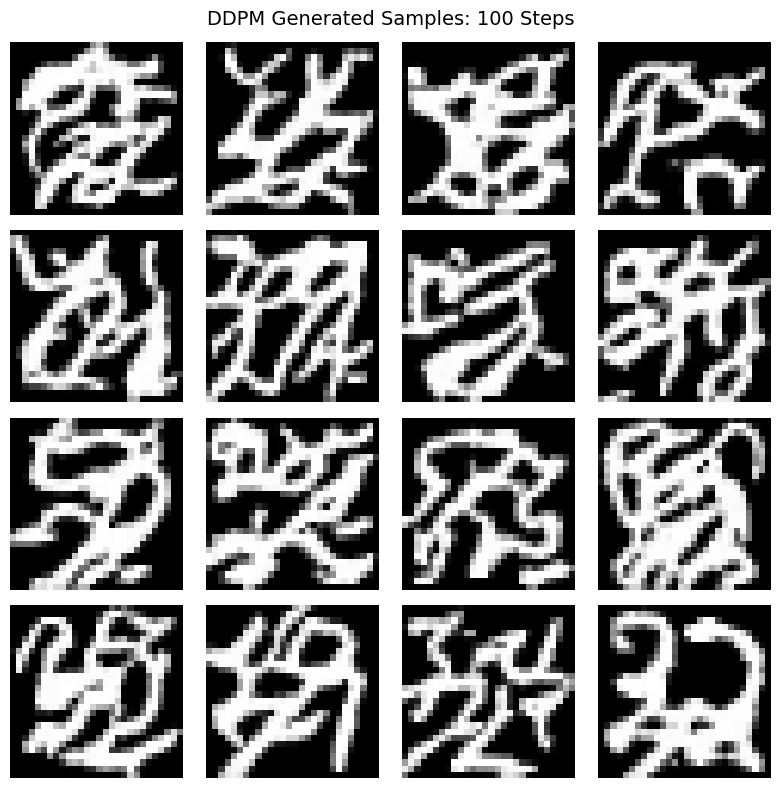

In [19]:
ddpm_display = ddpm_samples.detach().cpu()
ddpm_display = torch.clamp(ddpm_display, -1, 1)
ddpm_display = (ddpm_display + 1) / 2

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        ddpm_display[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

plt.suptitle(
    "DDPM Generated Samples: 100 Steps",
    fontsize=14
)

plt.tight_layout()
plt.show()

### DDPM Sampling Observation

The first trained CNN achieved a low noise prediction loss, but DDPM sampling revealed poor global image structure. The generated samples contain locally digit like strokes but frequently overlap or extend across the image instead of forming isolated MNIST digits. This indicates that noise prediction loss alone is not sufficient to evaluate generative quality. The baseline CNN primarily uses same resolution convolutions, which limits its ability to capture broader spatial structure. A revised architecture with a larger effective receptive field will therefore be evaluated.

In [20]:
class ImprovedNoisePredictor(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()

        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.ReLU(),
            nn.Linear(time_dim, time_dim),
            nn.ReLU()
        )

        self.time_down = nn.Linear(time_dim, 64)
        self.time_middle = nn.Linear(time_dim, 128)
        self.time_up = nn.Linear(time_dim, 64)

        self.conv1 = nn.Conv2d(
            1,
            32,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            32,
            64,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            64,
            128,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.conv4 = nn.Conv2d(
            128,
            128,
            kernel_size=3,
            padding=1
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.conv5 = nn.Conv2d(
            128,
            64,
            kernel_size=3,
            padding=1
        )

        self.up2 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.conv6 = nn.Conv2d(
            64,
            32,
            kernel_size=3,
            padding=1
        )

        self.output = nn.Conv2d(
            32,
            1,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, t):
        t_normalized = t.float().unsqueeze(1) / T
        t_embedding = self.time_mlp(t_normalized)

        x1 = F.relu(self.conv1(x))

        x2 = F.relu(self.conv2(x1))
        time_down = self.time_down(t_embedding)
        x2 = x2 + time_down[:, :, None, None]

        x3 = F.relu(self.conv3(x2))
        time_middle = self.time_middle(t_embedding)
        x3 = x3 + time_middle[:, :, None, None]

        x3 = F.relu(self.conv4(x3))

        x = F.relu(self.up1(x3))
        time_up = self.time_up(t_embedding)
        x = x + time_up[:, :, None, None]

        x = torch.cat([x, x2], dim=1)
        x = F.relu(self.conv5(x))

        x = F.relu(self.up2(x))

        x = torch.cat([x, x1], dim=1)
        x = F.relu(self.conv6(x))

        return self.output(x)


improved_model = ImprovedNoisePredictor().to(device)

num_parameters = sum(
    p.numel()
    for p in improved_model.parameters()
    if p.requires_grad
)

print(improved_model)
print()
print(f"Trainable parameters: {num_parameters:,}")

ImprovedNoisePredictor(
  (time_mlp): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (time_down): Linear(in_features=64, out_features=64, bias=True)
  (time_middle): Linear(in_features=64, out_features=128, bias=True)
  (time_up): Linear(in_features=64, out_features=64, bias=True)
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (up1): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (conv5): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (up2): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (conv6): Conv2d(64, 32, kernel_size=(

In [21]:
test_x = images[:8].to(device)

test_t = torch.randint(
    0,
    T,
    (test_x.size(0),),
    device=device,
    dtype=torch.long
)

with torch.no_grad():
    test_output = improved_model(
        test_x,
        test_t
    )

print("Input shape:", test_x.shape)
print("Timestep shape:", test_t.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == test_x.shape
assert torch.isfinite(test_output).all()

print("Improved model checks passed.")

Input shape: torch.Size([8, 1, 28, 28])
Timestep shape: torch.Size([8])
Output shape: torch.Size([8, 1, 28, 28])
Improved model checks passed.


In [22]:
SANITY_EPOCHS = 5

sanity_optimizer = torch.optim.Adam(
    improved_model.parameters(),
    lr=LEARNING_RATE
)

sanity_losses = []

sanity_start_time = time.time()

for epoch in range(SANITY_EPOCHS):
    improved_model.train()

    epoch_start_time = time.time()
    running_loss = 0.0

    for batch_images, _ in train_loader:
        batch_images = batch_images.to(device)

        batch_size = batch_images.size(0)

        t = torch.randint(
            0,
            T,
            (batch_size,),
            device=device,
            dtype=torch.long
        )

        noisy_images, true_noise = forward_diffusion(
            batch_images,
            t
        )

        predicted_noise = improved_model(
            noisy_images,
            t
        )

        loss = criterion(
            predicted_noise,
            true_noise
        )

        sanity_optimizer.zero_grad()
        loss.backward()
        sanity_optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)
    sanity_losses.append(average_loss)

    epoch_time = time.time() - epoch_start_time

    print(
        f"Sanity Epoch {epoch + 1:02d}/{SANITY_EPOCHS} | "
        f"Loss: {average_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

sanity_total_time = time.time() - sanity_start_time

print()
print("Sanity training complete")
print(f"Initial sanity loss: {sanity_losses[0]:.6f}")
print(f"Final sanity loss: {sanity_losses[-1]:.6f}")
print(f"Total sanity time: {sanity_total_time:.2f}s")

Sanity Epoch 01/5 | Loss: 0.181950 | Time: 14.69s
Sanity Epoch 02/5 | Loss: 0.096474 | Time: 14.63s
Sanity Epoch 03/5 | Loss: 0.084236 | Time: 14.14s
Sanity Epoch 04/5 | Loss: 0.079249 | Time: 14.72s
Sanity Epoch 05/5 | Loss: 0.076367 | Time: 14.16s

Sanity training complete
Initial sanity loss: 0.181950
Final sanity loss: 0.076367
Total sanity time: 72.35s


In [23]:
improved_training_losses = sanity_losses.copy()
improved_epoch_times = []

remaining_start_time = time.time()

for epoch in range(5, 50):
    improved_model.train()

    epoch_start_time = time.time()
    running_loss = 0.0

    for batch_images, _ in train_loader:
        batch_images = batch_images.to(device)

        batch_size = batch_images.size(0)

        t = torch.randint(
            0,
            T,
            (batch_size,),
            device=device,
            dtype=torch.long
        )

        noisy_images, true_noise = forward_diffusion(
            batch_images,
            t
        )

        predicted_noise = improved_model(
            noisy_images,
            t
        )

        loss = criterion(
            predicted_noise,
            true_noise
        )

        sanity_optimizer.zero_grad()
        loss.backward()
        sanity_optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)
    improved_training_losses.append(average_loss)

    epoch_time = time.time() - epoch_start_time
    improved_epoch_times.append(epoch_time)

    print(
        f"Epoch {epoch + 1:02d}/50 | "
        f"Loss: {average_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

remaining_training_time = time.time() - remaining_start_time
improved_total_training_time = sanity_total_time + remaining_training_time

best_improved_epoch = int(np.argmin(improved_training_losses)) + 1
best_improved_loss = min(improved_training_losses)

improved_loss_reduction = (
    (improved_training_losses[0] - improved_training_losses[-1])
    / improved_training_losses[0]
) * 100

print()
print("Improved model training complete")
print(f"Initial epoch loss: {improved_training_losses[0]:.6f}")
print(f"Final epoch loss: {improved_training_losses[-1]:.6f}")
print(f"Best loss: {best_improved_loss:.6f}")
print(f"Best epoch: {best_improved_epoch}")
print(f"Loss reduction: {improved_loss_reduction:.2f}%")
print(f"Total training time: {improved_total_training_time:.2f}s")

Epoch 06/50 | Loss: 0.074960 | Time: 14.66s
Epoch 07/50 | Loss: 0.072803 | Time: 13.71s
Epoch 08/50 | Loss: 0.071331 | Time: 14.01s
Epoch 09/50 | Loss: 0.070983 | Time: 13.89s
Epoch 10/50 | Loss: 0.069593 | Time: 14.35s
Epoch 11/50 | Loss: 0.068228 | Time: 14.18s
Epoch 12/50 | Loss: 0.068052 | Time: 14.46s
Epoch 13/50 | Loss: 0.066963 | Time: 14.41s
Epoch 14/50 | Loss: 0.066602 | Time: 14.63s
Epoch 15/50 | Loss: 0.066359 | Time: 14.35s
Epoch 16/50 | Loss: 0.065303 | Time: 14.29s
Epoch 17/50 | Loss: 0.065661 | Time: 14.14s
Epoch 18/50 | Loss: 0.064544 | Time: 14.23s
Epoch 19/50 | Loss: 0.064738 | Time: 14.40s
Epoch 20/50 | Loss: 0.064600 | Time: 14.31s
Epoch 21/50 | Loss: 0.064609 | Time: 14.41s
Epoch 22/50 | Loss: 0.063476 | Time: 14.12s
Epoch 23/50 | Loss: 0.064422 | Time: 14.27s
Epoch 24/50 | Loss: 0.062740 | Time: 14.43s
Epoch 25/50 | Loss: 0.063566 | Time: 14.10s
Epoch 26/50 | Loss: 0.063276 | Time: 14.46s
Epoch 27/50 | Loss: 0.062863 | Time: 14.59s
Epoch 28/50 | Loss: 0.062149 | T

In [24]:
improved_ddpm_start_time = time.time()

improved_ddpm_samples = ddpm_sample(
    improved_model,
    num_samples=16
)

improved_ddpm_sampling_time = (
    time.time() - improved_ddpm_start_time
)

print(
    "Generated sample shape:",
    improved_ddpm_samples.shape
)

print(
    f"DDPM sampling time: "
    f"{improved_ddpm_sampling_time:.4f} seconds"
)

print(
    "Contains NaN:",
    torch.isnan(improved_ddpm_samples).any().item()
)

print(
    "Sample range:",
    improved_ddpm_samples.min().item(),
    "to",
    improved_ddpm_samples.max().item()
)

Generated sample shape: torch.Size([16, 1, 28, 28])
DDPM sampling time: 0.2366 seconds
Contains NaN: False
Sample range: -1.0569051504135132 to 1.0399733781814575


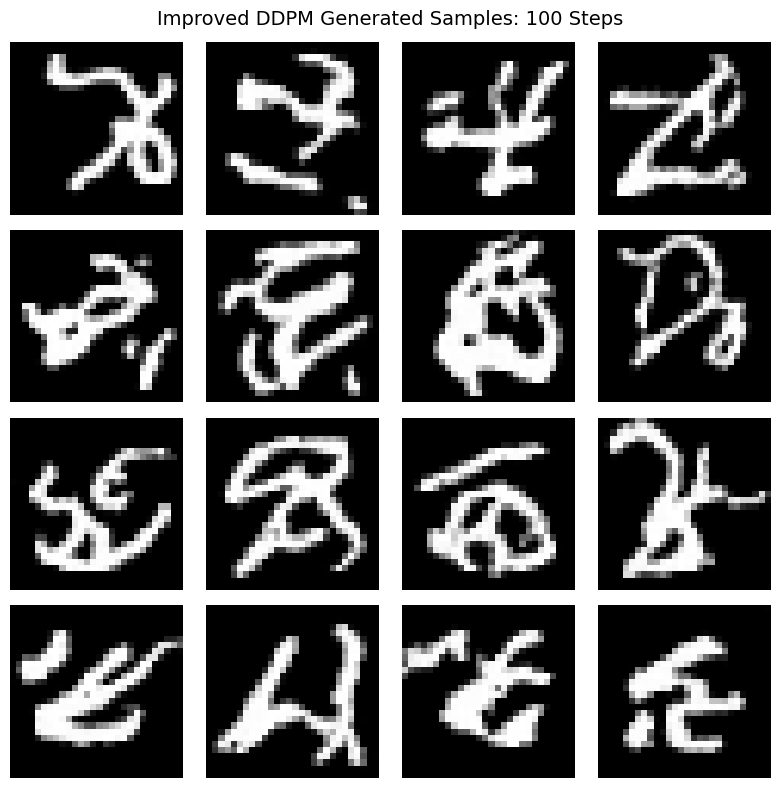

In [25]:
improved_ddpm_display = (
    improved_ddpm_samples
    .detach()
    .cpu()
)

improved_ddpm_display = torch.clamp(
    improved_ddpm_display,
    -1,
    1
)

improved_ddpm_display = (
    improved_ddpm_display + 1
) / 2

fig, axes = plt.subplots(
    4,
    4,
    figsize=(8, 8)
)

for i, ax in enumerate(axes.flat):
    ax.imshow(
        improved_ddpm_display[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

plt.suptitle(
    "Improved DDPM Generated Samples: 100 Steps",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [26]:
improved_checkpoint = {
    "model_state_dict": improved_model.state_dict(),
    "optimizer_state_dict": sanity_optimizer.state_dict(),
    "training_losses": improved_training_losses,
    "num_epochs": 50,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "T": T,
    "beta_start": beta_start,
    "beta_end": beta_end,
    "best_loss": best_improved_loss,
    "best_epoch": best_improved_epoch
}

torch.save(
    improved_checkpoint,
    "HW8_improved_ddpm_checkpoint.pt"
)

print("Improved DDPM checkpoint saved successfully.")

Improved DDPM checkpoint saved successfully.


### Improved DDPM Sampling Observation

The revised network produced more coherent and spatially localized structures than the initial baseline model. Several generated samples contain recognizable digit like shapes, although some samples remain distorted or ambiguous.

The improved model also achieved a lower best training loss than the baseline model. However, the sampling results demonstrate that a low noise prediction MSE does not necessarily correspond to perfectly recognizable generated digits.

One limitation is the intentionally small diffusion configuration required for this assignment. With only 100 diffusion steps and the specified linear beta schedule, the final forward diffusion state still retains substantial information from the original image. In contrast, reverse generation begins from Gaussian noise. This simplified configuration makes the generation task more difficult than larger diffusion setups while keeping the implementation computationally manageable.

## Part D: DDIM Sampling

DDIM modifies the reverse sampling procedure so that images can be generated using fewer sampling steps. The same trained noise prediction network is used, but the reverse trajectory skips selected diffusion timesteps. In this experiment, deterministic DDIM sampling is evaluated using 50 and 20 steps and compared with 100 step DDPM sampling.

In [27]:
@torch.no_grad()
def ddim_sample(model, num_samples=16, num_steps=50):
    model.eval()

    x = torch.randn(
        num_samples,
        1,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=device
    )

    timesteps = torch.linspace(
        T - 1,
        0,
        num_steps,
        device=device
    ).long()

    for i, t_index in enumerate(timesteps):
        t_value = int(t_index.item())

        t = torch.full(
            (num_samples,),
            t_value,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        alpha_bar_t = alpha_bars[t_value]

        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        if i == len(timesteps) - 1:
            x = predicted_x0
        else:
            next_t_value = int(timesteps[i + 1].item())
            alpha_bar_next = alpha_bars[next_t_value]

            x = (
                torch.sqrt(alpha_bar_next) * predicted_x0
                + torch.sqrt(1.0 - alpha_bar_next) * predicted_noise
            )

    return x

In [28]:
ddim_50_start = time.time()

ddim_50_samples = ddim_sample(
    improved_model,
    num_samples=16,
    num_steps=50
)

ddim_50_time = time.time() - ddim_50_start


ddim_20_start = time.time()

ddim_20_samples = ddim_sample(
    improved_model,
    num_samples=16,
    num_steps=20
)

ddim_20_time = time.time() - ddim_20_start


print("DDIM 50 step results")
print("Shape:", ddim_50_samples.shape)
print(f"Sampling time: {ddim_50_time:.4f} seconds")
print(
    "Contains NaN:",
    torch.isnan(ddim_50_samples).any().item()
)

print()

print("DDIM 20 step results")
print("Shape:", ddim_20_samples.shape)
print(f"Sampling time: {ddim_20_time:.4f} seconds")
print(
    "Contains NaN:",
    torch.isnan(ddim_20_samples).any().item()
)

DDIM 50 step results
Shape: torch.Size([16, 1, 28, 28])
Sampling time: 0.1354 seconds
Contains NaN: False

DDIM 20 step results
Shape: torch.Size([16, 1, 28, 28])
Sampling time: 0.0499 seconds
Contains NaN: False


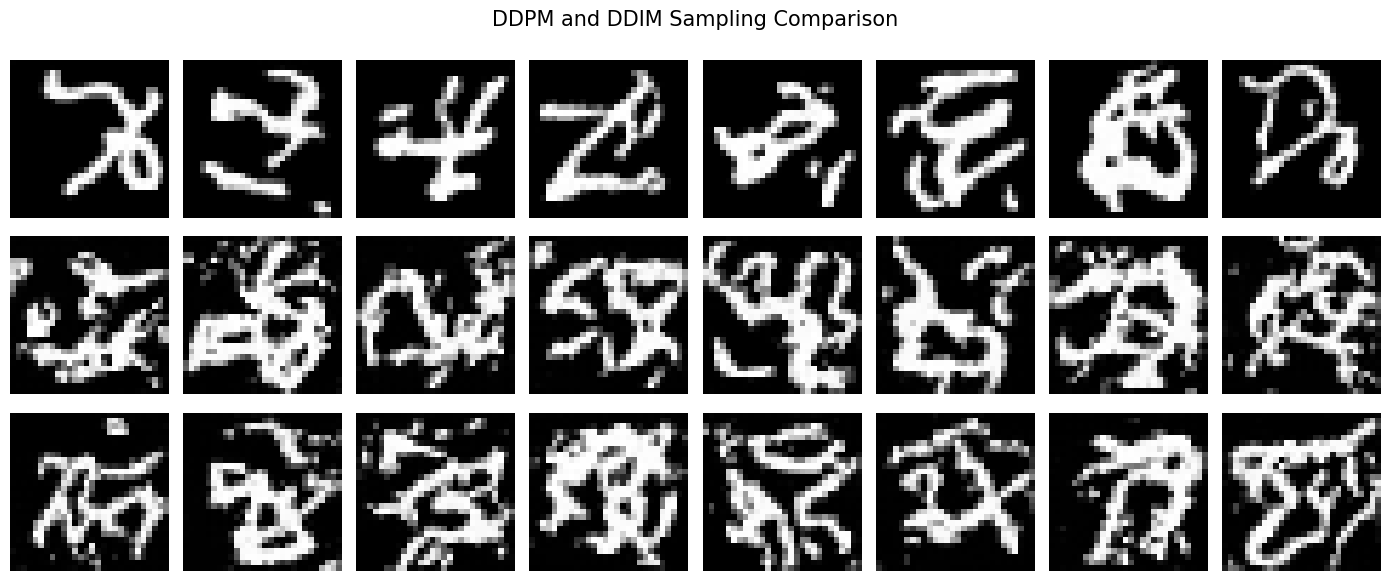

In [29]:
def prepare_for_display(samples):
    samples = samples.detach().cpu()
    samples = torch.clamp(samples, -1, 1)
    return (samples + 1) / 2


ddpm_vis = prepare_for_display(improved_ddpm_samples)
ddim_50_vis = prepare_for_display(ddim_50_samples)
ddim_20_vis = prepare_for_display(ddim_20_samples)


fig, axes = plt.subplots(
    3,
    8,
    figsize=(14, 6)
)

methods = [
    ("DDPM: 100 Steps", ddpm_vis),
    ("DDIM: 50 Steps", ddim_50_vis),
    ("DDIM: 20 Steps", ddim_20_vis)
]

for row, (title, samples) in enumerate(methods):
    for col in range(8):
        axes[row, col].imshow(
            samples[col].squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        title,
        fontsize=11,
        rotation=90,
        labelpad=15
    )

plt.suptitle(
    "DDPM and DDIM Sampling Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [30]:
speedup_50 = (
    improved_ddpm_sampling_time
    / ddim_50_time
)

speedup_20 = (
    improved_ddpm_sampling_time
    / ddim_20_time
)

reduction_50 = (
    1
    - ddim_50_time / improved_ddpm_sampling_time
) * 100

reduction_20 = (
    1
    - ddim_20_time / improved_ddpm_sampling_time
) * 100


print("Sampling Performance")
print("=" * 40)

print(
    f"DDPM 100 steps: "
    f"{improved_ddpm_sampling_time:.4f} seconds"
)

print(
    f"DDIM 50 steps:  "
    f"{ddim_50_time:.4f} seconds"
)

print(
    f"DDIM 20 steps:  "
    f"{ddim_20_time:.4f} seconds"
)

print()

print(
    f"DDIM 50 speedup: "
    f"{speedup_50:.2f}x"
)

print(
    f"DDIM 20 speedup: "
    f"{speedup_20:.2f}x"
)

print(
    f"DDIM 50 time reduction: "
    f"{reduction_50:.2f}%"
)

print(
    f"DDIM 20 time reduction: "
    f"{reduction_20:.2f}%"
)

Sampling Performance
DDPM 100 steps: 0.2366 seconds
DDIM 50 steps:  0.1354 seconds
DDIM 20 steps:  0.0499 seconds

DDIM 50 speedup: 1.75x
DDIM 20 speedup: 4.74x
DDIM 50 time reduction: 42.77%
DDIM 20 time reduction: 78.89%


### DDPM and DDIM Comparison

The 100 step DDPM sampler produced the most coherent outputs overall, although several generated samples remained ambiguous or distorted. DDIM reduced the number of reverse diffusion evaluations substantially. Using 50 DDIM steps reduced sampling time from 0.2366 seconds to 0.1354 seconds, corresponding to a 1.75x speedup and a 42.77% reduction in sampling time.

Reducing DDIM sampling to 20 steps decreased the sampling time further to 0.0499 seconds. This corresponds to a 4.74x speedup and a 78.89% reduction compared with 100 step DDPM sampling.

The generated samples show a tradeoff between computational efficiency and image quality. DDPM uses all 100 reverse steps and generally preserves more coherent digit like structure. DDIM with 50 steps generates samples considerably faster while retaining some recognizable structure. At 20 steps, DDIM is substantially faster, but the generated samples are more distorted and ambiguous.

These results demonstrate the primary advantage of DDIM in this experiment: the trained noise prediction network can be reused with a reduced sampling trajectory, allowing substantially faster generation without retraining the model.